# Percentils, Bootstrapping and Confidence Intervals

This notebook reviews Lecture 23: Confidence Intervals and Lecture 24: Interpreting Confidence. 

**Helpful Resource:**
- [Python Reference](http://data8.org/sp22/python-reference.html): Cheat sheet of helpful array & table methods used in Data 8!

**Recommended Readings**: 
- [Percentiles](https://inferentialthinking.com/chapters/13/1/Percentiles.html)
- [Bootstrap](https://inferentialthinking.com/chapters/13/2/Bootstrap.html)
- [Confidence Intervals](https://inferentialthinking.com/chapters/13/3/Confidence_Intervals.html)

In [243]:
from datascience import *
%matplotlib inline
path_data = '../../../assets/data/'
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
from math import ceil

## Estimation

Recap, a parameter is a numerical value associated with population, such as mean, median, standard deviation, etc. In other words, a parameter is a charactistic of a population.

Almost always, parameters that we are interested are unknown. But we can use percentiles, bootstrapping and confidence interval to estimate the parameters of a population. Percentiles are mathematical tools. Bootstrapping is a simulation tool. Confidence interval is a estimation tool.

### Percentiles

Percentiles are positions from 0% to 100%.

Let p be a number between 0 and 100. The pth percentile of a collection is the smallest value in the collection that is at least as large as p% of all the values.

By this definition, any percentile between 0 and 100 can be computed for any collection of values, and it is always an element of the collection.

In practical terms, suppose there are n elements in the collection. To find the pth percentile:

- Sort the collection in increasing order.
- Find p% of n: (p/100) * n. Call that k.
- If k is an integer, take the kth element of the sorted collection.
- If k is not an integer, round it up to the next integer, and take that element of the sorted collection.

### The Bootstrap: Resampling from the Sample

#### How bootstapping works?
By the law of averages, the distribution of the original sample is likely to resemble the population, and the distributions of all the “resamples” are likely to resemble the original sample. So the distributions of all the resamples are likely to resemble the population as well.

1. Treat the original sample as if it were the population.
2. Draw from the sample, at random with replacement, the same number of times as the original sample size.

**Use `tbl.sample()` with replacement to redraw samples from the sample distribution**

We can use bootstrapping to determine confidence interval.

### Percentiles Example

Use the student data to identify the 20th, 40th, 60th, and 80th quartile of the height. Calculate your answers in two ways: once using the `percentile` function provided by the `datascience` package, and a second time by using the definition of percentiles. The position $L$ in a sorted list for the k-th percentile is given by: 

Find p% of n: 

$k = \frac{p}{100} * n$

If $k$ is not an integer, you can use the `ceil` function in the `math` package to round $k$ up to the next greater integer. 

In [244]:
students = Table.read_table('student_data.csv')
students.show(3)

SEX,COLOR,ZIP,MATH,PAPER,CAR,SHOE,AGE,HEIGHT,PETS,SOCIAL
Female,Blue,95403,3,2,2018,6.5,20,61,0,Yes
Female,Other,95401,2,5,2007,6.5,26,61,1,No
Female,Green,95492,1,3,1994,5.5,22,62,4,Yes


In [245]:
students.column("AGE")

array([20, 26, 22, 19, 19, 37, 17, 18, 36, 20, 18, 18, 22, 24, 24, 19, 26,
       19, 18, 17, 19, 18, 17, 19, 23, 21, 23, 20, 22, 15, 25, 21, 22, 22,
       20, 18, 44, 49, 49, 18, 28, 18, 18, 19, 19, 18, 25, 18, 27, 25, 20,
       22, 20, 25, 18, 20, 19, 25, 19, 28, 21, 18, 26, 20, 20, 18, 18, 19,
       19, 23, 18, 30, 26, 23])

#### `percentile()` datascience function

`percentile(percentile, array)`

Returns the corresponding percentile of an array.

In [246]:
# sort the array and return the corresponding percentile of an array.
percentile(10, students.column("AGE"))

18

In [247]:
# 20th, 40th, 60th, and 80th

print("20th :", percentile(20, students.column("AGE")))
print("40th :", percentile(40, students.column("AGE")))
print("60th :", percentile(60, students.column("AGE")))
print("80th :", percentile(80, students.column("AGE")))

20th : 18
40th : 19
60th : 22
80th : 25


In [248]:
# compute percentiles using formula
ages = students.sort("AGE").column("AGE")
ages

array([15, 17, 17, 17, 18, 18, 18, 18, 18, 18, 18, 18, 18, 18, 18, 18, 18,
       18, 18, 18, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 20, 20,
       20, 20, 20, 20, 20, 20, 20, 21, 21, 21, 22, 22, 22, 22, 22, 22, 23,
       23, 23, 23, 24, 24, 25, 25, 25, 25, 25, 26, 26, 26, 26, 27, 28, 28,
       30, 36, 37, 44, 49, 49])

In [249]:
_20th = 20 / 100 * len(ages)
print("20th :", ages.item(ceil(_20th)))

_40th = 40 / 100 * len(ages)
print("40th :", ages.item(ceil(_40th)))

_60th = 60 / 100 * len(ages)
print("60th :", ages.item(ceil(_60th)))

_80th = 80 / 100 * len(ages)
print("80th :", ages.item(ceil(_80th)))

20th : 18
40th : 19
60th : 22
80th : 25


The `boxplot` shows some of the important percentiles from a given set of data. Run the following code to examine the boxplot of the student height data. How do your percentiles compare with these? 

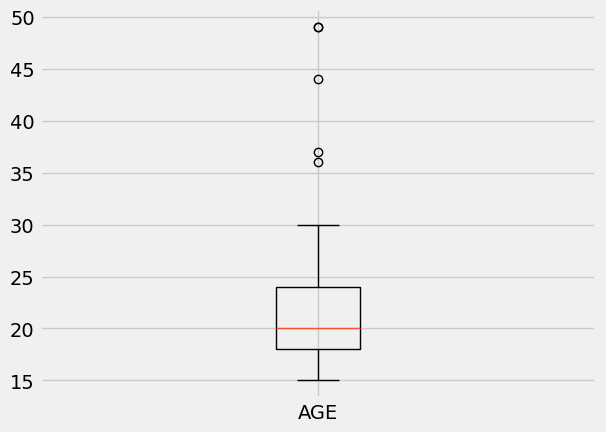

In [250]:
# boxplot() captures the max and min boundary, outliners, 
#   25th, 50th and 75th percentiles and the middle 50% of the data
students.select('AGE').boxplot()

In [251]:
percentile(50, students.column("AGE"))

20

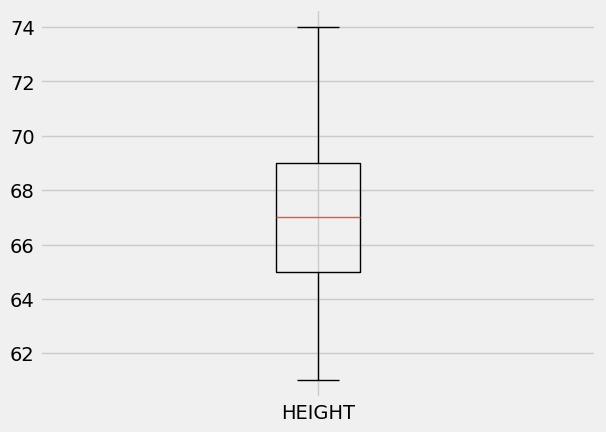

In [252]:
students.select('HEIGHT').boxplot()

### Bootstrapping Example Tech Salaries

Parameter: the median of the tech salaries

In [184]:
tech_salaries = Table.read_table("tech_salaries.csv")
tech_salaries.show(3)

Title,Company,Location,Salary
Software Engineer,eBay,"San Francisco, CA",100000
Software Engineer,Microsoft,"Mountain View, CA",157000
Software Engineer,Microsoft,"Seattle, WA",208000


In [185]:
# check max and min salaries
(tech_salaries.column('Salary').max(), tech_salaries.column('Salary').min())

(4490000, 30000)

In [259]:
original_sample.sort('Salary', descending=False)

Title,Company,Location,Salary
Software Engineer,Zomato,"Gurgaon, HR, India",30000
Software Engineer,Arcesium,"Hyderabad, TS, India",31000
Software Engineer,VMware,"Bengaluru, KA, India",38000
Software Engineer,ADP,"Porto Alegre, RS, Brazil",39000
Software Engineer,VMware,"Bengaluru, KA, India",39000
Software Engineer,Microsoft,"Hyderabad, AP, India",41000
Software Engineer,Goldman Sachs,"Bangalore, KA, India",44000
Software Engineer,Zscaler,"Bengaluru, KA, India",45000
Software Engineer,Microsoft,"Belgrade, SR, Serbia",45000
Software Engineer,VMware,"Bengaluru, KA, India",45000


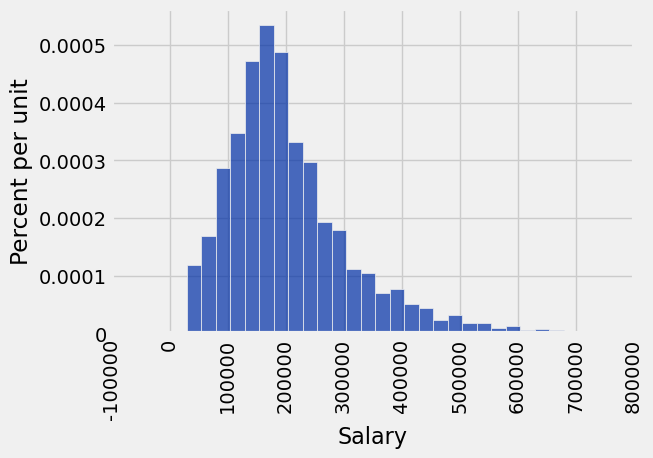

In [186]:
# check the overall data distribution
tech_salaries.hist('Salary', bins=np.arange(30000, 700001, 25000))

As mentioned previously, bootstrapping, percentiles and confidence interval are tools to estimate the parameters of a population. Almost always, we don't the real parameters. But, since we have the entire dataset, we can take a look.

In [204]:
# check the real salary median from the dataset
salary_median = percentile(50, tech_salaries.column('Salary'))
salary_median

183000

#### A Random Sample and an Estimate

Draw a large sample of high tech salaries at random **without replacement**. We draw without replacement because this is our original sample, we will be using it for bootstrapping. We want each data point is unique from the population.

In [205]:
original_sample = tech_salaries.sample(700, with_replacement=False)
original_sample.show(3)

Title,Company,Location,Salary
Software Engineer,eBay,"Seattle, WA",186000
Software Engineer,VMware,"Bengaluru, KA, India",38000
Software Engineer,UBS,"London, EN, United Kingdom",202000


In [206]:
# check the max and min the original_sample
(original_sample.column('Salary').max(), original_sample.column('Salary').min())

(990000, 30000)

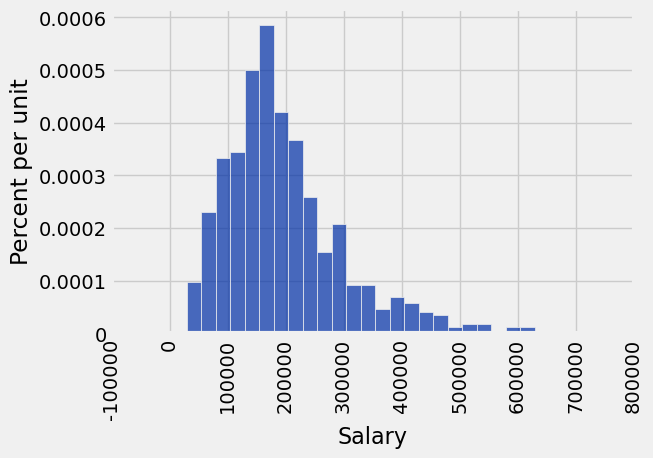

In [207]:
first_sample.select('Salary').hist(bins=np.arange(30000, 700001, 25000))

In [208]:
# check the salary median from the first sample
original_sample_median = percentile(50, original_sample.column('Salary'))
original_sample_median

180000

The sample size is large. By the law of averages, the distribution of the sample resembles that of the population. 

#### Bootstrap: Resampling from the Sample

We are going to resample from the original sample that we drew from the entire population. It is call resampling from the sample. The subsequence resamplings in a simulation will also be drawn from the original sample, not the population.

1. Treat the original sample as if it were the population.
2. Draw from the sample, at random with replacement, the same number of times as the original sample size.

In [218]:
# let see how it goes with the first resampling
#   by default, tbl.sample() draws with replacement and the sample size is the size of the table
re_sample_1 = original_sample.sample()
re_sample_1.show(3)

Title,Company,Location,Salary
Software Engineer,Google,"Sunnyvale, CA",408000
Software Engineer,Raytheon,"Denver, CO",87000
Software Engineer,Goldman Sachs,"London, EN, United Kingdom",160000


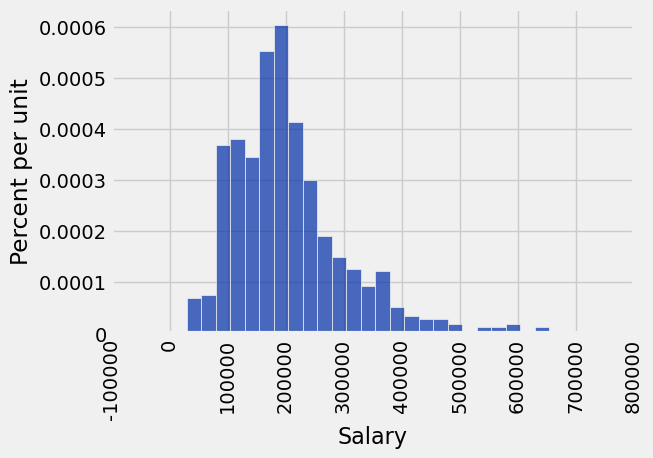

In [219]:
# check the histogram
re_sample_1.select('Salary').hist(bins=np.arange(30000, 700001, 25000))

In [220]:
re_sampled_median_1 = percentile(50, re_sample_1.column('Salary'))
re_sampled_median_1

189000

Becasue of the law of averages, the distribution of the original sample is likely to resemble the population, and the distributions of all the “resamples” are likely to resemble the original sample.

In [221]:
print(f"salary_median:", salary_median, "original_sample_median:", original_sample_median, "re_sampled_median_1:", re_sampled_median_1)

salary_median: 183000 original_sample_median: 180000 re_sampled_median_1: 189000


We can keep resampling from the original sample over and over again.
Let's create functions to simulate bootstripping.

In [222]:
# function to bootstrap 1 median
def one_bootstrap_median():
    re_sampled_table = original_sample.sample()
    bootstrapped_median = percentile(50, re_sampled_table.column('Salary'))
    return bootstrapped_median

In [223]:
one_bootstrap_median()

185000

#### Bootstrap Empirical Distribution of the Sample Median

In [237]:
repeats = 7000
bootstrap_medians = make_array()
for i in np.arange(repeats):
    bootstrap_medians = np.append (bootstrap_medians, one_bootstrap_median())

In [238]:
(max(bootstrap_medians), min(bootstrap_medians))

(195000.0, 170000.0)

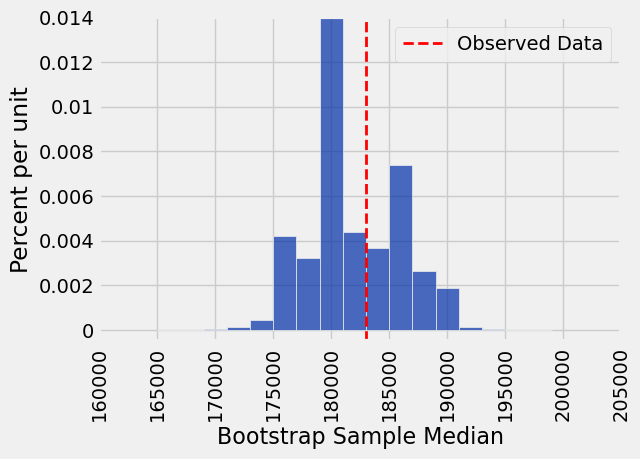

In [242]:
re_sampled_medians = Table().with_column('Bootstrap Sample Median', bootstrap_medians)
median_bins=np.arange(165000, 200000, 2000)
re_sampled_medians.hist(bins = median_bins)

# Plotting parameters; you can ignore this code
parameter_green = '#32CD32'
plots.ylim(-0.000005, 0.00014)
#plots.scatter(salary_median, 0, color=parameter_green, s=40, zorder=2);
plots.axvline(salary_median, color='red', linestyle='--', linewidth=2, label='Observed Data')
plots.legend()

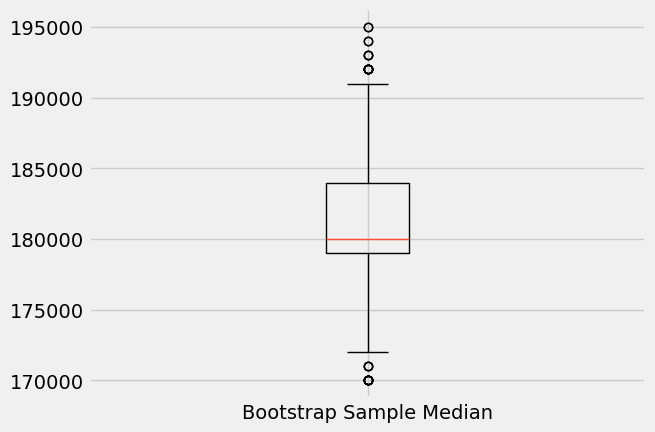

In [254]:
# let's check it with boxplot()
re_sampled_medians.select('Bootstrap Sample Median').boxplot()

### Bootstrapping

Prices of 10 textbooks are shown below. 

In [ ]:
ten_books = make_array(35, 83, 102, 58, 91, 155, 205, 220, 120, 67, 99)

Find the sample mean. 

Use `table.sample` to create a bootstrap sample. Does your sample contain any repeated values? Is this a problem? 

Find the mean of this bootstrap sample. 

Repeat this process and save the mean of each boostrap sample in an array. 

Where is the center of these means? What values identify the middle 95% of these means? 

### Confidence Intervals from Previous Simulations

What percentage of Americans believe in global warming?  A survey on 2,251 randomly selected individuals conducted in October 2020 found that 1,328 answered Yes to the question “Is there solid evidence of global warming?”   A bootstrap distribution for this data is shown.  

<img src="bootstrap_proportion.png" width=600>

What does each value represent in this graph? 

Use the information in the graph to give and interpret a 95% CI for the proportion of Americans who believe there is solid evidence of global warming. (Note: you can use the closest values on the X-axis to approximate the middle 95% of the total area) 

A survey of 50 four-year colleges in the U.S. shows their tuition in 2020. Based on this sample, bootstrapping was used to resample from the 50 colleges and the distribution of the bootstrap sample means is shown below. 
<img src="bootstrap_mean.GIF" width=800>

Use this graph to derive the 95% confidence interval of the mean tuition cost in U.S. 4-year colleges. 

### Constructing a Confidence Interval for a Single Mean

The following code uses the student data to create a bootstrap confidence interval for the average age. In the usage of ```table.sample```, is it doing sampling with or without replacement?  What would happen otherwise?   

In [ ]:
bootstrap_means = make_array()
for i in np.arange(5000):
    resampled_mean = np.average(students.sample().column('AGE'))
    bootstrap_means = np.append(bootstrap_means, resampled_mean)

Table().with_column('bootstrap means', bootstrap_means).hist()

Use the `bootstrap_means` array and `percentile` function to compute the 90%, 95% and 99% confidence intervals for the average age. 

In [ ]:
# you can draw the interval on the histogram by using plots.plot([left, right], [0, 0], color='red', lw=8);
# 90% confidence interval


# 95% C.I.


# 99% C.I.


### Confidence Interval for a Difference of Two Means

Can you modify the simulation above to use bootstrapping to construct a confidence interval between the average height of male and female students? (Note: you can use ```average_male - average_female``` as the bootstrap statistic)

Using the NBA data to construct a 95% confidence interval for the average salary of players in 2020 and compare it with the 2010 season.  

In [ ]:
nba = Table.read_table('nba_salaries.csv')
nba20 = nba.where('season', are.equal_to(2020))
nba10 = nba.where('season', are.equal_to(2010))

In [ ]:
def average_salary_bootstrap(table):
    bootstrap_means = make_array()
    for i in np.arange(5000):
        resampled_mean = np.average(table.sample().column('salary'))
        bootstrap_means = np.append(bootstrap_means, resampled_mean)
    return bootstrap_means

means20 = average_salary_bootstrap(nba20)
means10 = average_salary_bootstrap(nba10)

Use the NBA data, can you find how many percent of all the players play the Center (C) position in 2020 v.s. 2010?

### Confidence Interval for Proportions 

The sample proportions can be seen as the mean of a binary variable, where $X=1$ represents the heads of a coin toss, and $X=0$ otherwise. This variable is automatically created when you use ```np.count_nonzero```. For example, suppose a sample of $n=10$ consists of 7 people who voted ``yes`` (represented by 1) and 3 who voted for ``no`` (represented by 0), then the percentage of people who voted ``yes`` will be the average of these binary values. 

In [ ]:
# a set of binary data 
voters = make_array(0, 1, 1, 0, 1, 1, 0, 1, 1, 1)
# the mean of these data is exactly the proportion of 1s, which is 0.7
# these two ways of calculating the proportion are equivalent
print(np.average(voters), sum(voters)/len(voters))

# we can also bootstrap the proportion of 1s in the voters array
t = Table().with_column('Vote', voters)
bootstrap_prop = make_array()
for i in np.arange(10000):
    bootstrap_prop = np.append(bootstrap_prop, np.average(t.sample().column('Vote')))
Table().with_column("bootstrap proportions", bootstrap_prop).hist()
np.average(bootstrap_prop)

As a more realistic example, to construct a confidence interval for the proportion of students who use social media, we use the following code to generate the bootstrap distribution. 

In [ ]:
bootstrap_props = make_array()
for i in np.arange(5000):
    resampled_prop = np.count_nonzero(students.sample().column('SOCIAL') == 'Yes') / students.num_rows
    bootstrap_props = np.append(bootstrap_props, resampled_prop)
Table().with_column('sample props', bootstrap_props).hist()

In [ ]:
percentile(2.5, bootstrap_props), percentile(97.5, bootstrap_props)

Use the NBA data to produce 95% confidence intervals for the proportion of centers in 2020 v.s. 2010.

In [ ]:
def prop_center_bootstrap(table):
    bootstrap_props = make_array()
    for i in np.arange(5000):
        resampled_prop = np.count_nonzero(table.sample().column('position') == 'C') / table.num_rows
        bootstrap_props = np.append(bootstrap_props, resampled_prop)
    return bootstrap_props


Based on these confidence intervals, is there an evidence that the percentage of centers in NBA changed significantly from 2010 to 2020? 

Here is a recent survey from Pew Research with regard to how Americans view the military action in Iran. The description of the methodology can be found [here](https://www.pewresearch.org/politics/2026/03/25/iran-methodology/). Construct a 99% bootstrapping confidence interval of the percentage of Americans who disapprove of the president's handling of the conflict. 

In [ ]:
# Data from Pew Research Center's March 2026 survey of 3,524 Americans
# About 6-in-10 Americans (61%) disapprove the president's handling of the conflict, while 37% approve.

iran_data = Table().with_column("Disapprove", np.concatenate([np.ones(round(3524*0.61)), np.zeros(round(3524*0.39))]))


Based on your interval, is there evidence that the majority of the public is apposed to the war? 